In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV,train_test_split,cross_val_predict,cross_val_score
from sklearn.metrics import r2_score,mean_absolute_error,mean_absolute_percentage_error,mean_squared_error
from sklearn.linear_model import LinearRegression,Ridge,Lasso

# EDA

## this data has genetical_risk column which was not there in the previous data frame

In [2]:
df=pd.read_excel('data/premiums_young_with_gr.xlsx')
df.head()

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount,Genetical_Risk
0,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365,4
1,22,Female,Northwest,Unmarried,0,Underweight,No Smoking,Freelancer,<10L,3,No Disease,Silver,11050,3
2,21,Female,Southeast,Unmarried,0,Normal,Regular,Salaried,> 40L,97,No Disease,Silver,11857,4
3,25,Male,Southeast,Unmarried,0,Normal,No Smoking,Freelancer,10L - 25L,15,No Disease,Bronze,5684,2
4,20,Male,Southeast,Unmarried,2,Overweight,No Smoking,Freelancer,10L - 25L,14,No Disease,Bronze,5712,1


In [3]:
df.shape

(20096, 14)

In [4]:
df.columns

Index(['Age', 'Gender', 'Region', 'Marital_status', 'Number Of Dependants',
       'BMI_Category', 'Smoking_Status', 'Employment_Status', 'Income_Level',
       'Income_Lakhs', 'Medical History', 'Insurance_Plan',
       'Annual_Premium_Amount', 'Genetical_Risk'],
      dtype='object')

In [5]:
df.columns=df.columns.str.replace(' ','_').str.lower()
df.columns

Index(['age', 'gender', 'region', 'marital_status', 'number_of_dependants',
       'bmi_category', 'smoking_status', 'employment_status', 'income_level',
       'income_lakhs', 'medical_history', 'insurance_plan',
       'annual_premium_amount', 'genetical_risk'],
      dtype='object')

In [6]:
df.dtypes

age                       int64
gender                   object
region                   object
marital_status           object
number_of_dependants      int64
bmi_category             object
smoking_status           object
employment_status        object
income_level             object
income_lakhs              int64
medical_history          object
insurance_plan           object
annual_premium_amount     int64
genetical_risk            int64
dtype: object

# Data transformation

## Handel Null Values

In [7]:
df.isnull().sum()

age                      0
gender                   0
region                   0
marital_status           0
number_of_dependants     0
bmi_category             0
smoking_status           2
employment_status        1
income_level             4
income_lakhs             0
medical_history          0
insurance_plan           0
annual_premium_amount    0
genetical_risk           0
dtype: int64

In [8]:
df.dropna(inplace=True)# droping every null value

In [9]:
df.duplicated().sum()# finding duplicate values
# df.drop_duplicates(inplace=True) if u want to delete the duplicate values

np.int64(0)

In [10]:
round(df.describe(),2)

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
count,20090.00,20090.00,20090.00,20090.00,20090.00
mean,21.49,0.72,22.51,8142.10,2.50
std,2.29,0.94,23.42,2749.91,1.71
min,18.00,-3.00,1.00,3501.00,0.00
25%,19.00,0.00,6.00,6022.25,1.00
50%,22.00,0.00,16.00,7939.00,3.00
75%,23.00,1.00,31.00,9561.00,4.00
max,25.00,3.00,790.00,18186.00,5.00


In [11]:
df[df.number_of_dependants<0].shape

(22, 14)

## number_of_dependants column tranformation

In [12]:
df[df.number_of_dependants<0]['number_of_dependants'].unique() # ask your data engineer about those negative values, he said they are positive values but while collecting data some mistake happened,so convert those negative values to positive

array([-3, -1])

In [13]:
df['number_of_dependants']=abs(df['number_of_dependants'])# converting negative values to positive
df[df.number_of_dependants<0]

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk


In [14]:
df.number_of_dependants.describe()

count    20090.000000
mean         0.722598
std          0.937200
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          3.000000
Name: number_of_dependants, dtype: float64

In [15]:
df.select_dtypes(['float64','int64'])# getting numarical values

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
0,18,0,99,13365,4
1,22,0,3,11050,3
2,21,0,97,11857,4
3,25,0,15,5684,2
4,20,2,14,5712,1
...,...,...,...,...,...
20091,18,0,91,11603,1
20092,23,0,57,14498,2
20093,24,0,35,9111,5
20094,21,0,32,8564,4


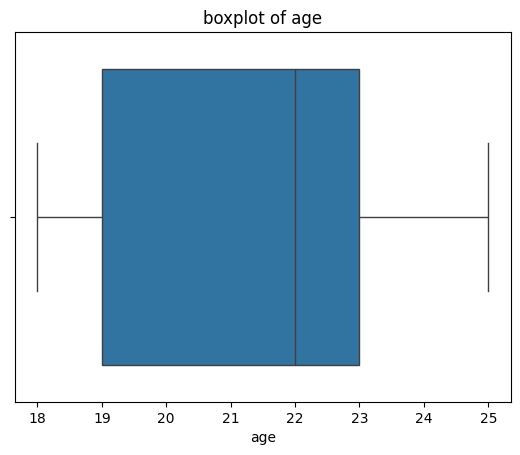

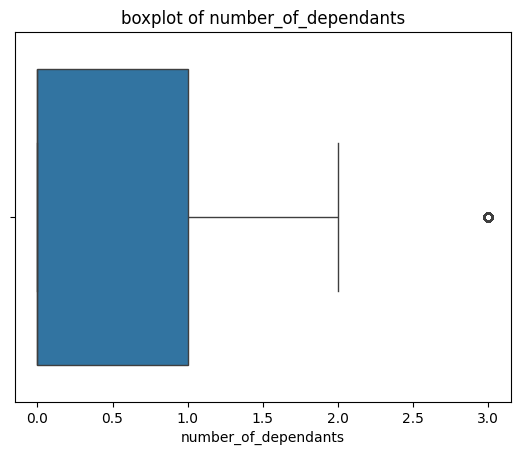

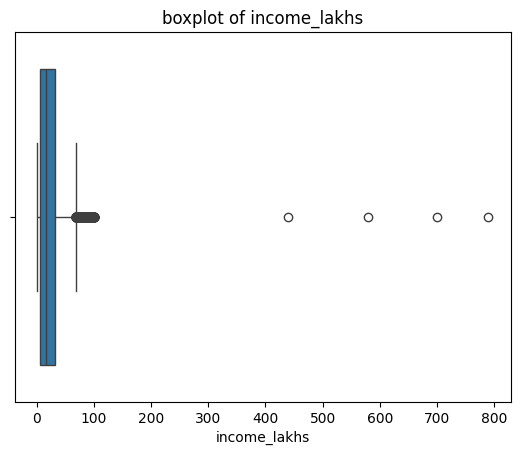

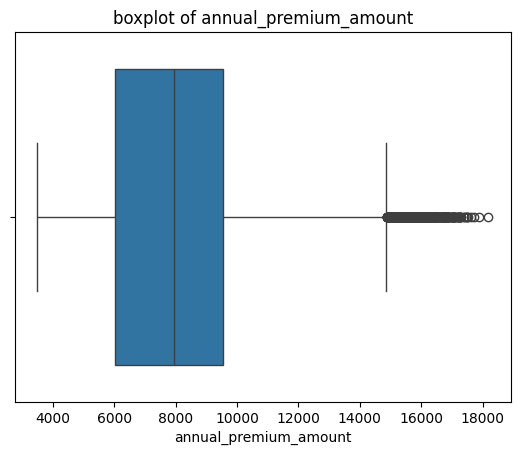

In [16]:
box =['age', 'number_of_dependants', 'income_lakhs',
       'annual_premium_amount']
for col in box:
    sns.boxplot(x=df[col])
    plt.title(f'boxplot of {col}')
    plt.show()

## removing outliers in age column

In [17]:
df[df['age']>100]['age'].unique()

array([], dtype=int64)

In [18]:
df1=df[df['age']<=100].copy()
df1.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
count,20090.000000,20090.000000,20090.000000,20090.000000,20090.000000
mean,21.494375,0.722598,22.510851,8142.096267,2.503932
std,2.294052,0.937200,23.420493,2749.906347,1.710203
min,18.000000,0.000000,1.000000,3501.000000,0.000000
25%,19.000000,0.000000,6.000000,6022.250000,1.000000
50%,22.000000,0.000000,16.000000,7939.000000,3.000000
75%,23.000000,1.000000,31.000000,9561.000000,4.000000
max,25.000000,3.000000,790.000000,18186.000000,5.000000


## using IQR to remove outliers in income_lakhs

<Axes: xlabel='income_lakhs', ylabel='Count'>

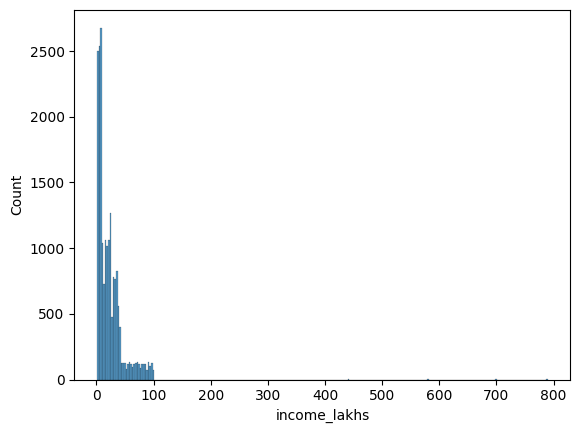

In [19]:
sns.histplot(df1['income_lakhs'])

In [20]:
def get_iqr(col):
    q1,q3=col.quantile([.25,.75])
    iqr=q3-q1
    lower_bound=q1-1.5*iqr
    upper_bound=q3+1.5*iqr
    return lower_bound,upper_bound

In [21]:
get_iqr(df1['income_lakhs'])

(-31.5, 68.5)

In [22]:
quantile_thresold=df1['income_lakhs'].quantile(0.999)
quantile_thresold

np.float64(100.0)

In [23]:
df1[df1['income_lakhs']>quantile_thresold]

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk
1677,22,Female,Northwest,Unmarried,0,Underweight,No Smoking,Freelancer,> 40L,440,No Disease,Silver,10636,3
4311,20,Female,Southwest,Unmarried,0,Normal,No Smoking,Freelancer,> 40L,580,Thyroid,Silver,12888,5
4661,21,Female,Southwest,Unmarried,0,Obesity,No Smoking,Freelancer,> 40L,700,No Disease,Bronze,7424,3
6251,21,Female,Southeast,Unmarried,0,Normal,Occasional,Salaried,> 40L,790,No Disease,Silver,7586,0


In [24]:
df1[df1['income_lakhs']>quantile_thresold].shape

(4, 14)

In [25]:
df2=df1[df1.income_lakhs<=quantile_thresold].copy()
df2.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
count,20086.000000,20086.000000,20086.000000,20086.000000,20086.000000
mean,21.494474,0.722742,22.390371,8141.799263,2.503883
std,2.294248,0.937238,21.732062,2749.912486,1.710184
min,18.000000,0.000000,1.000000,3501.000000,0.000000
25%,19.000000,0.000000,6.000000,6022.000000,1.000000
50%,22.000000,0.000000,16.000000,7939.000000,3.000000
75%,23.000000,1.000000,31.000000,9561.000000,4.000000
max,25.000000,3.000000,100.000000,18186.000000,5.000000


In [26]:
box

['age', 'number_of_dependants', 'income_lakhs', 'annual_premium_amount']

## Understanding dataset with the help of graphs

### Observe the plots, you can see the relations (correlation) of the columns

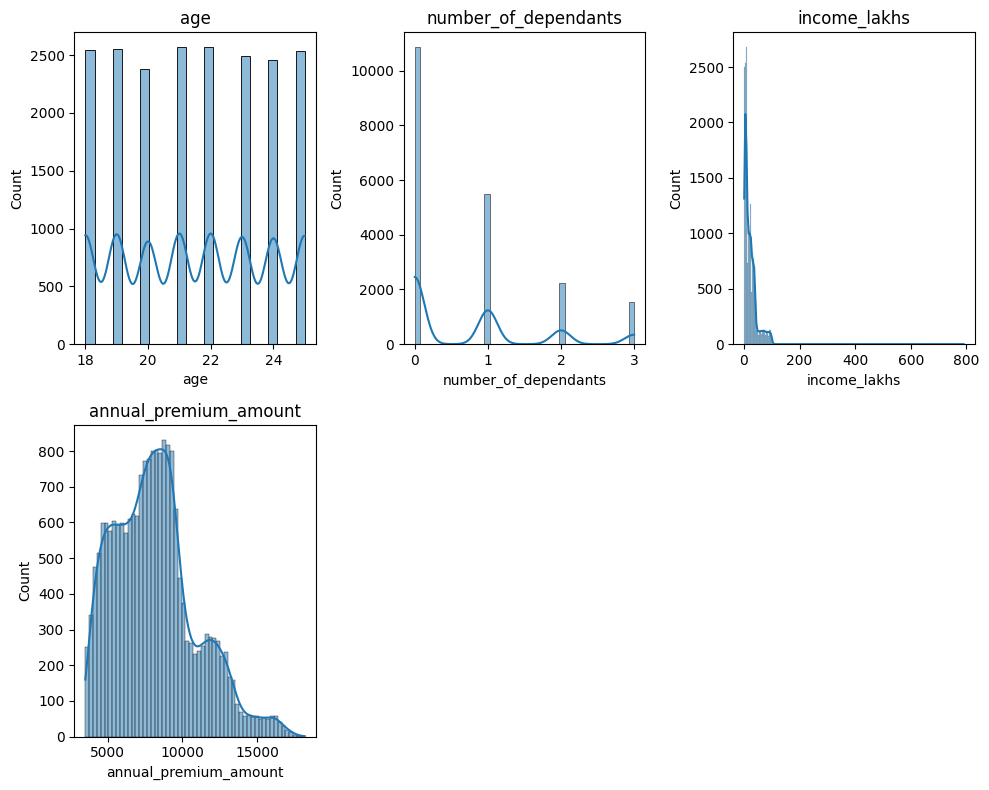

In [27]:
fig,axs=plt.subplots(nrows=2,ncols=3,figsize=(10,8))
for i,col in enumerate(box):
    ax=axs[i//3,i%3]
    sns.histplot(df1[col],kde=True,ax=ax)
    ax.set_title(col)
if len(box)%3!=0:
    for j in range(len(box),6):
        axs.flat[j].set_visible(False)
plt.tight_layout()
plt.show()
#plots with outliers

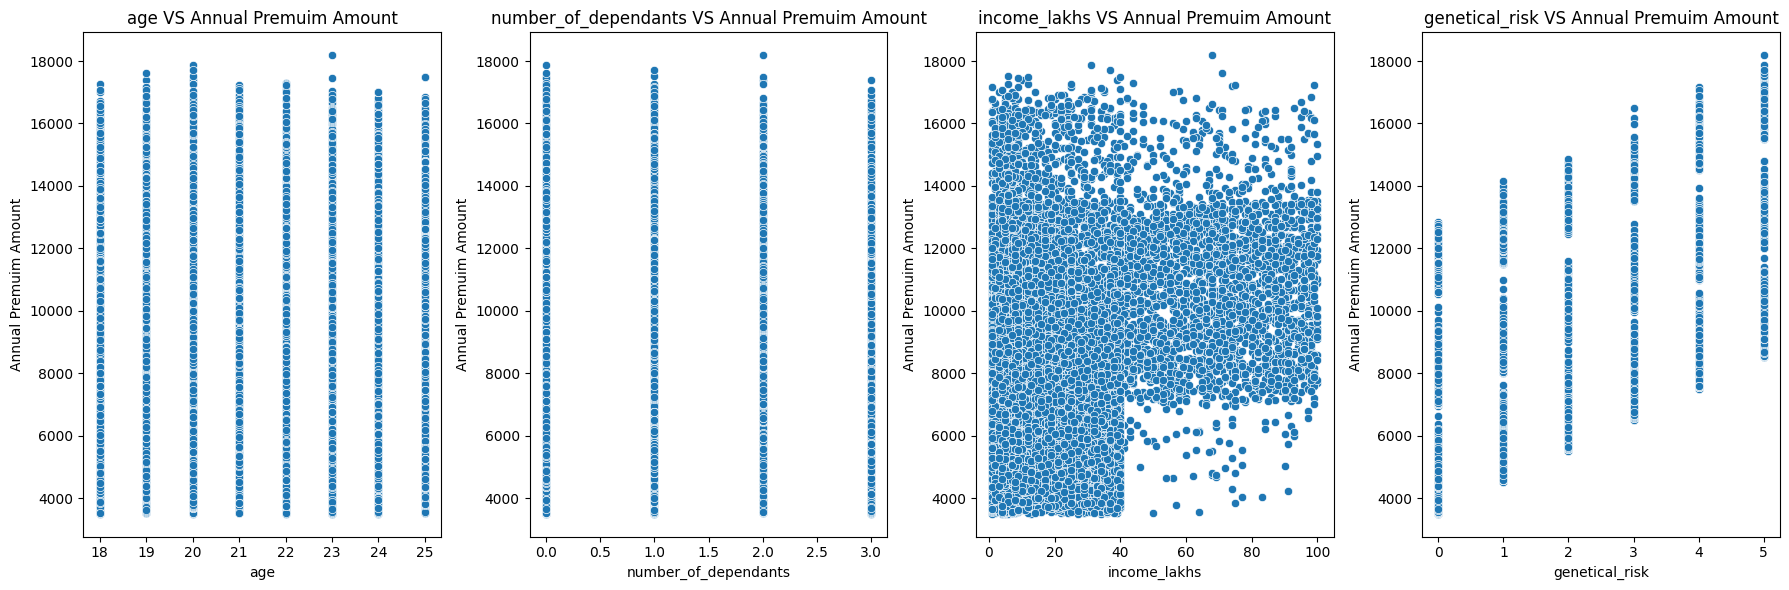

In [28]:
num=['age', 'number_of_dependants', 'income_lakhs','genetical_risk']#independent numeric columns
fig,axes=plt.subplots(1,len(num),figsize=(18,6))
for ax,col in zip(axes,num):
    sns.scatterplot(x=df2[col],y=df2['annual_premium_amount'],ax=ax)
    ax.set_title(f'{col} VS Annual Premuim Amount')
    ax.set_xlabel(col)
    ax.set_ylabel('Annual Premuim Amount')
plt.tight_layout()
plt.show()

In [29]:
categorical=df2.select_dtypes('string')
categorical.columns

Index([], dtype='object')

In [30]:
categorical_col=['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status','employment_status', 'income_level', 'medical_history','insurance_plan']
for col in categorical_col:
    print(col, ":",df2[col].unique())
#here in smoking_status column we got some error values ('Smoking=0','Does Not Smoke','Not Smoking')all mean the same

gender : ['Male' 'Female']
region : ['Northeast' 'Northwest' 'Southeast' 'Southwest']
marital_status : ['Unmarried' 'Married']
bmi_category : ['Overweight' 'Underweight' 'Normal' 'Obesity']
smoking_status : ['Regular' 'No Smoking' 'Occasional' 'Smoking=0' 'Does Not Smoke'
 'Not Smoking']
employment_status : ['Self-Employed' 'Freelancer' 'Salaried']
income_level : ['> 40L' '<10L' '10L - 25L' '25L - 40L']
medical_history : ['High blood pressure' 'No Disease' 'Diabetes & High blood pressure'
 'Diabetes & Heart disease' 'Diabetes' 'Diabetes & Thyroid'
 'Heart disease' 'Thyroid' 'High blood pressure & Heart disease']
insurance_plan : ['Silver' 'Bronze' 'Gold']


In [31]:
df2['smoking_status'].unique()

array(['Regular', 'No Smoking', 'Occasional', 'Smoking=0',
       'Does Not Smoke', 'Not Smoking'], dtype=object)

In [32]:
df2['smoking_status']=df2['smoking_status'].replace({
    'Smoking=0':'No Smoking',
    'Does Not Smoke':'No Smoking',
    'Not Smoking':'No Smoking'
},inplace=True)

C:\Users\Jeevan kumar\AppData\Local\Temp\ipykernel_22464\949633080.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2['smoking_status']=df2['smoking_status'].replace({


In [33]:
df2['smoking_status'].unique()

array([None], dtype=object)

In [34]:
df2['gender'].value_counts(normalize=True)

gender
Male      0.550383
Female    0.449617
Name: proportion, dtype: float64

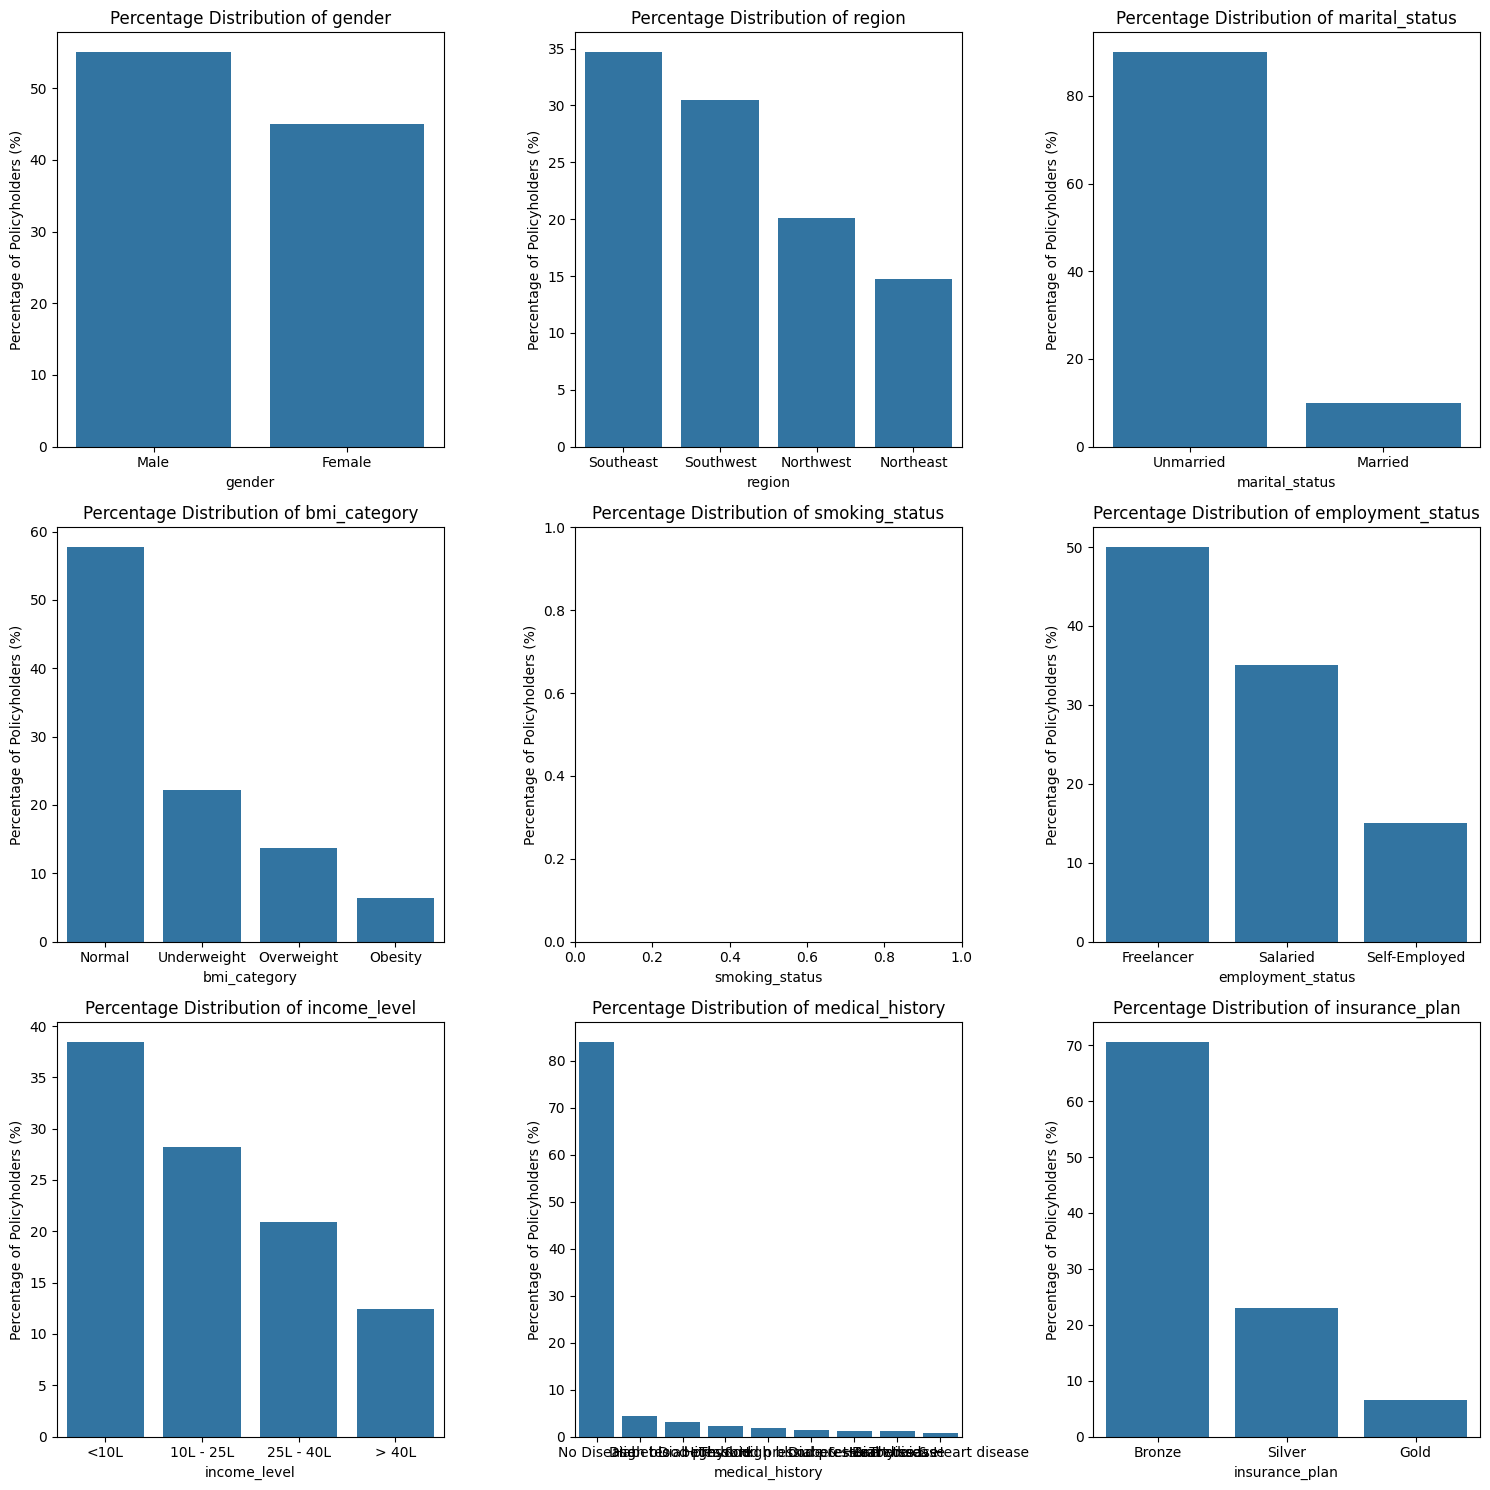

In [35]:
fig,axes=plt.subplots(3,3,figsize=(15,15))
axes=axes.flatten()
for ax,col in zip(axes,categorical_col):
    categorical_count=df2[col].value_counts(normalize=True)*100
    sns.barplot(x=categorical_count.index,y=categorical_count.values,ax=ax)
    ax.set_title(f'Percentage Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Percentage of Policyholders (%)')
plt.tight_layout()
plt.show()

<Axes: xlabel='income_level'>

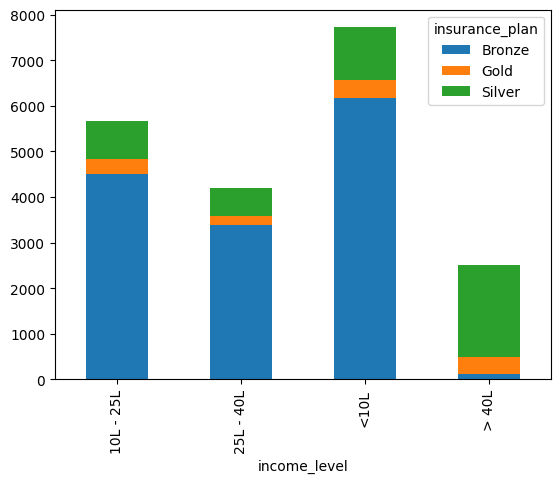

In [36]:
corsstab=pd.crosstab(df2['income_level'],df2['insurance_plan'])

corsstab.plot(kind='bar',stacked=True)

<Axes: xlabel='insurance_plan', ylabel='income_level'>

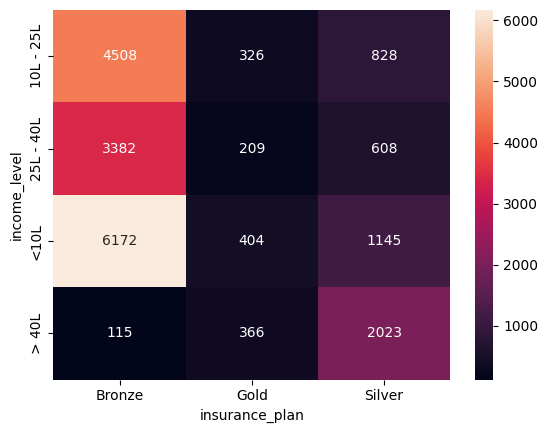

In [37]:
sns.heatmap(corsstab,annot=True,fmt='d')

# Feature Engineering

In [38]:
df2.head(2)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk
0,18,Male,Northeast,Unmarried,0,Overweight,None,Self-Employed,> 40L,99,High blood pressure,Silver,13365,4
1,22,Female,Northwest,Unmarried,0,Underweight,None,Freelancer,<10L,3,No Disease,Silver,11050,3


In [39]:
df2.medical_history.unique()

array(['High blood pressure', 'No Disease',
       'Diabetes & High blood pressure', 'Diabetes & Heart disease',
       'Diabetes', 'Diabetes & Thyroid', 'Heart disease', 'Thyroid',
       'High blood pressure & Heart disease'], dtype=object)

In [40]:
df2['medical_history'].str.split('&',expand=True).apply(lambda x:x.str.lower())

,0,1
0,high blood pressure,None
1,no disease,None
2,no disease,None
3,no disease,None
4,no disease,None
...,...,...
20091,no disease,None
20092,diabetes,None
20093,no disease,None
20094,no disease,None


In [41]:
df2[['disease1','disease2']]=df2['medical_history'].str.split('&',expand=True).apply(lambda x:x.str.lower())

In [42]:
df2.columns

Index(['age', 'gender', 'region', 'marital_status', 'number_of_dependants',
       'bmi_category', 'smoking_status', 'employment_status', 'income_level',
       'income_lakhs', 'medical_history', 'insurance_plan',
       'annual_premium_amount', 'genetical_risk', 'disease1', 'disease2'],
      dtype='object')

In [43]:
risk_score={
    'diabetes':6,
    'heart disease':8,
    'high blood pressure':6,
    'thyroid':5,
    'no disease':0,
    'none':0
}

In [44]:
df2['disease1'] = df2['disease1'].fillna('none')
df2['disease2'] = df2['disease2'].fillna('none')
df2['total_risk_score'] = 0

In [45]:
for disease in ['disease1','disease2']:
    df2['total_risk_score']+=df2[disease].map(risk_score)

max_score=df2['total_risk_score'].max()
min_score=df2['total_risk_score'].min()
df2['normalized_risk_score']=(df2['total_risk_score']-min_score)/(max_score-min_score)
df2.head(2)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk,disease1,disease2,total_risk_score,normalized_risk_score
0,18,Male,Northeast,Unmarried,0,Overweight,None,Self-Employed,> 40L,99,High blood pressure,Silver,13365,4,high blood pressure,none,6.0,0.75
1,22,Female,Northwest,Unmarried,0,Underweight,None,Freelancer,<10L,3,No Disease,Silver,11050,3,no disease,none,0.0,0.00


In [46]:
df2.sample(15)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk,disease1,disease2,total_risk_score,normalized_risk_score
19461,23,Female,Southeast,Unmarried,1,Obesity,None,Salaried,<10L,4,No Disease,Silver,9505,1,no disease,none,0.0,0.00
7311,19,Male,Southwest,Unmarried,1,Overweight,None,Self-Employed,25L - 40L,30,Diabetes,Bronze,9643,4,diabetes,none,6.0,0.75
18438,23,Male,Southeast,Unmarried,0,Normal,None,Salaried,10L - 25L,19,No Disease,Silver,12928,5,no disease,none,0.0,0.00
12501,24,Female,Southwest,Married,3,Overweight,None,Salaried,> 40L,86,No Disease,Silver,11545,4,no disease,none,0.0,0.00
16985,25,Male,Southeast,Unmarried,1,Normal,None,Salaried,> 40L,61,No Disease,Silver,8178,0,no disease,none,0.0,0.00
6439,18,Male,Southeast,Unmarried,0,Normal,None,Self-Employed,> 40L,48,No Disease,Silver,11967,4,no disease,none,0.0,0.00
10240,20,Female,Southwest,Unmarried,0,Normal,None,Freelancer,10L - 25L,10,No Disease,Bronze,4313,0,no disease,none,0.0,0.00
18310,19,Female,Southeast,Unmarried,1,Normal,None,Salaried,<10L,2,No Disease,Bronze,3659,0,no disease,none,0.0,0.00
9277,20,Male,Northwest,Unmarried,2,Obesity,None,Salaried,<10L,9,Diabetes & Thyroid,Silver,10100,1,diabetes,thyroid,NaN,NaN
19967,19,Female,Northwest,Married,2,Overweight,None,Freelancer,<10L,9,No Disease,Bronze,4720,0,no disease,none,0.0,0.00


In [47]:
df2['disease2'].value_counts()

disease2
none                    19082
 heart disease            417
 high blood pressure      353
 thyroid                  234
Name: count, dtype: int64

In [48]:
df2['insurance_plan'].value_counts()

insurance_plan
Bronze    14177
Silver     4604
Gold       1305
Name: count, dtype: int64

In [49]:
df2['insurance_plan']=df2['insurance_plan'].map({'Bronze':1,'Silver':2,'Gold':3})#encoding insurance_plan column
df2.insurance_plan.unique()

array([2, 1, 3])

In [50]:
df2['income_level']=df2['income_level'].map({'<10L':1,'10L - 25L':2,'25L - 40L':3,'> 40L':4})#encoding income_level column
df2['income_level'].unique()

array([4, 1, 2, 3])

In [52]:
nominal_cols=['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status','employment_status']#'medical_history', 'disease1', 'disease2' columns are not use here
df3=pd.get_dummies(df2,columns=nominal_cols,drop_first=True,dtype=int)#converting catogarical columns to numarical columns by using get_dummies
df3.head()

,age,number_of_dependants,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk,disease1,disease2,...,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
0,18,0,4,99,High blood pressure,2,13365,4,high blood pressure,none,...,1,0,0,0,1,0,1,0,0,1
1,22,0,1,3,No Disease,2,11050,3,no disease,none,...,0,1,0,0,1,0,0,1,0,0
2,21,0,4,97,No Disease,2,11857,4,no disease,none,...,0,0,1,0,1,0,0,0,1,0
3,25,0,2,15,No Disease,1,5684,2,no disease,none,...,1,0,1,0,1,0,0,0,0,0
4,20,2,2,14,No Disease,1,5712,1,no disease,none,...,1,0,1,0,1,0,1,0,0,0


In [53]:
df3.columns

Index(['age', 'number_of_dependants', 'income_level', 'income_lakhs',
       'medical_history', 'insurance_plan', 'annual_premium_amount',
       'genetical_risk', 'disease1', 'disease2', 'total_risk_score',
       'normalized_risk_score', 'gender_Male', 'region_Northwest',
       'region_Southeast', 'region_Southwest', 'marital_status_Unmarried',
       'bmi_category_Obesity', 'bmi_category_Overweight',
       'bmi_category_Underweight', 'employment_status_Salaried',
       'employment_status_Self-Employed'],
      dtype='object')

In [54]:
df4=df3.drop(['medical_history', 'disease1', 'disease2','total_risk_score'],axis=1)
df4.head()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,genetical_risk,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
0,18,0,4,99,2,13365,4,0.75,1,0,0,0,1,0,1,0,0,1
1,22,0,1,3,2,11050,3,0.00,0,1,0,0,1,0,0,1,0,0
2,21,0,4,97,2,11857,4,0.00,0,0,1,0,1,0,0,0,1,0
3,25,0,2,15,1,5684,2,0.00,1,0,1,0,1,0,0,0,0,0
4,20,2,2,14,1,5712,1,0.00,1,0,1,0,1,0,1,0,0,0


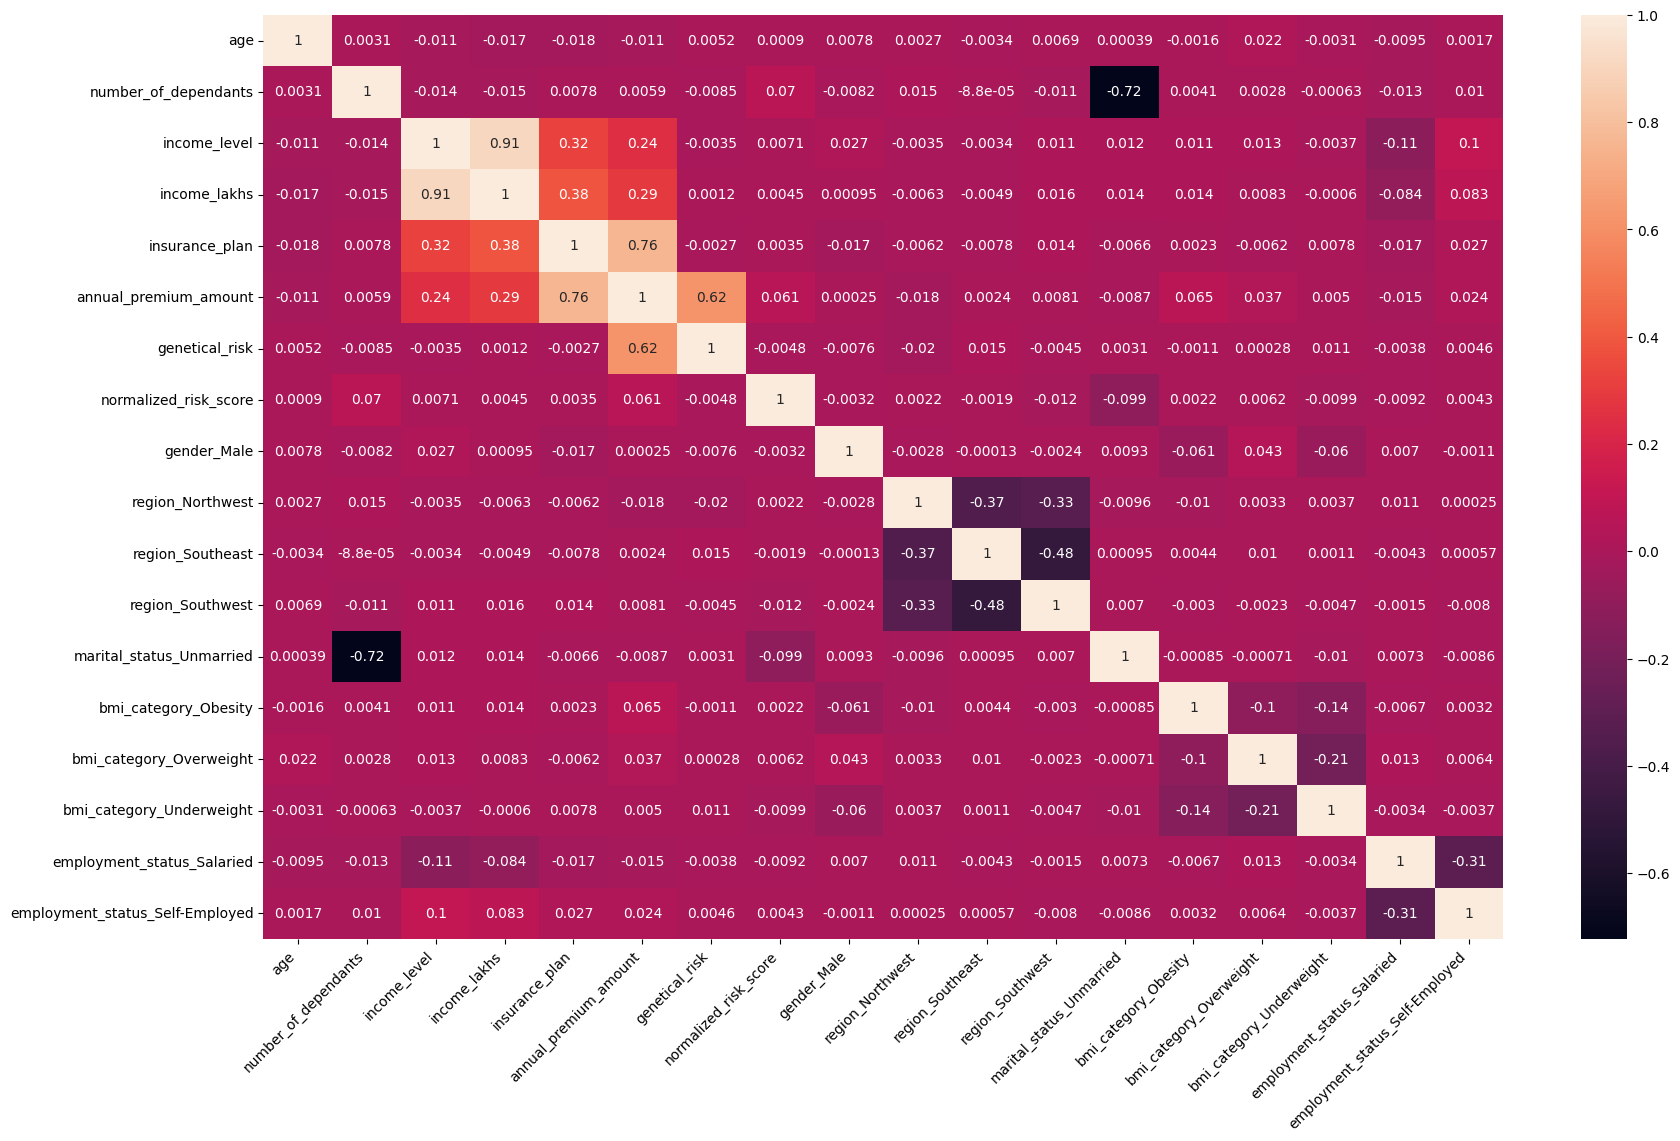

In [55]:
cn=df4.corr()

plt.figure(figsize=(20,12))
sns.heatmap(cn,annot=True)
plt.xticks(rotation=45,ha='right')
plt.yticks(rotation=0)
plt.tight_layout
plt.show()

In [56]:
#variation inflation factor

In [57]:
df4.head(2)

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,genetical_risk,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
0,18,0,4,99,2,13365,4,0.75,1,0,0,0,1,0,1,0,0,1
1,22,0,1,3,2,11050,3,0.00,0,1,0,0,1,0,0,1,0,0


In [58]:
x=df4.drop(columns='annual_premium_amount')
y=df4['annual_premium_amount']

from sklearn.preprocessing import MinMaxScaler
cols_to_scale=['age','number_of_dependants','income_level','income_lakhs','insurance_plan','genetical_risk']
scaler=MinMaxScaler()

x[cols_to_scale]=scaler.fit_transform(x[cols_to_scale])
x.describe()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,genetical_risk,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
count,20086.000000,20086.000000,20086.000000,20086.000000,20086.000000,20086.000000,19082.000000,20086.000000,20086.000000,20086.000000,20086.000000,20086.000000,20086.000000,20086.000000,20086.000000,20086.000000,20086.000000
mean,0.499211,0.240914,0.357994,0.216064,0.179578,0.500777,0.086757,0.550383,0.201284,0.346958,0.304590,0.899881,0.063527,0.136513,0.222493,0.350045,0.149955
std,0.327750,0.312413,0.347481,0.219516,0.300051,0.342037,0.242112,0.497467,0.400970,0.476014,0.460245,0.300167,0.243914,0.343341,0.415931,0.476996,0.357036
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.142857,0.000000,0.000000,0.050505,0.000000,0.200000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.571429,0.000000,0.333333,0.151515,0.000000,0.600000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.714286,0.333333,0.666667,0.303030,0.500000,0.800000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [59]:
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    data = data.copy() # Keep a copy of the data
    data = data.select_dtypes(include=np.number)# Keep only numeric columns
    data = data.replace([np.inf, -np.inf], np.nan)# Replace infinite values with NaN
    data = data.dropna() # Remove rows containing missing values
    data = data.loc[:, data.nunique() > 1] # Remove constant columns
    if data.shape[1] == 0:# Check whether any columns remain
        raise ValueError("No valid numeric columns available for VIF.")
    data = data.astype(float)# Convert to float
    # Calculate VIF
    vif_df = pd.DataFrame({
        'Column': data.columns,
        'VIF': [
            variance_inflation_factor(data.values, i)
            for i in range(data.shape[1])]})

    return vif_df.sort_values(by='VIF', ascending=False).reset_index(drop=True)

In [60]:
calculate_vif(x.drop(columns=['normalized_risk_score']))

,Column,VIF
0,income_lakhs,6.031327
1,income_level,5.800405
2,region_Southeast,2.193559
3,region_Southwest,2.136166
4,number_of_dependants,2.094816
5,marital_status_Unmarried,2.094079
6,region_Northwest,1.892938
7,insurance_plan,1.175298
8,employment_status_Salaried,1.115236
9,employment_status_Self-Employed,1.111452


In [61]:
x_reduced=x.drop(columns=['normalized_risk_score','income_level'])
x_reduced.head(2)

,age,number_of_dependants,income_lakhs,insurance_plan,genetical_risk,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,employment_status_Salaried,employment_status_Self-Employed
0,0.000000,0.0,0.989899,0.5,0.8,1,0,0,0,1,0,1,0,0,1
1,0.571429,0.0,0.020202,0.5,0.6,0,1,0,0,1,0,0,1,0,0


# Model training

In [62]:
x_train,x_test,y_train,y_test=train_test_split(x_reduced,y,test_size=.30,random_state=10)
print('x_train: ',x_train.shape)
print('x_test: ',x_test.shape)
print('y_train: ',y_train.shape)
print('y_test: ',x_test.shape)

x_train:  (14060, 15)
x_test:  (6026, 15)
y_train:  (14060,)
y_test:  (6026, 15)


In [63]:
model_l=LinearRegression()
model_l.fit(x_train,y_train)
model_l.score(x_test,y_test)

0.9718109853708154

In [64]:
model_l.score(x_train,y_train)#if score of train data set is higher,test score is lower,then the model is over fitting

0.9718710485863142

In [65]:
model_l.coef_

array([-1.50672713e+01,  7.93826882e+00, -2.89894281e+01,  7.00549180e+03,
        4.99875893e+03,  1.15679216e+02, -1.01773767e+01, -1.51748408e+01,
        1.33322830e+00, -3.42771049e+01,  8.26047414e+02,  4.07876603e+02,
        9.57647145e+01, -9.94070198e+00,  2.55691080e+00])

In [66]:
model_l.intercept_

np.float64(4240.100788757092)

In [67]:
feature_imp=model_l.coef_

coef_df=pd.DataFrame(feature_imp,index=x_test.columns,columns=['Coefficients'])
coef_df=coef_df.sort_values(by='Coefficients',ascending=True)
coef_df


,Coefficients
marital_status_Unmarried,-34.277105
income_lakhs,-28.989428
region_Southeast,-15.174841
age,-15.067271
region_Northwest,-10.177377
employment_status_Salaried,-9.940702
region_Southwest,1.333228
employment_status_Self-Employed,2.556911
number_of_dependants,7.938269
bmi_category_Underweight,95.764715


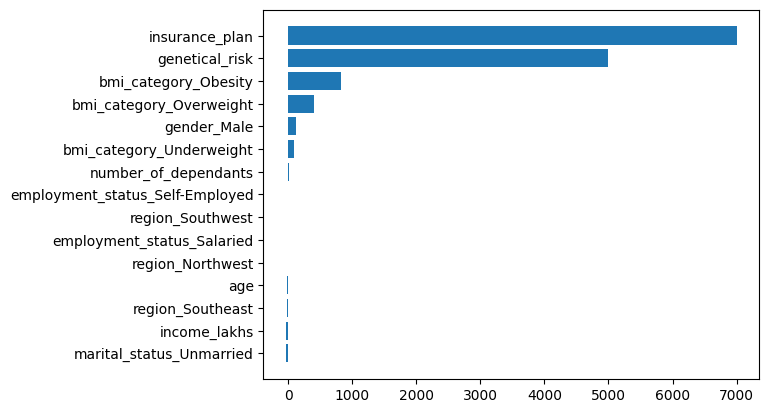

In [68]:
plt.barh(coef_df.index,coef_df['Coefficients'])
plt.show()

## Regularization

In [69]:
model_rg=Ridge(alpha=5)
model_rg.fit(x_train,y_train)
print('test score: ',model_rg.score(x_test,y_test))
print('train score: ',model_rg.score(x_train,y_train))

test score:  0.9718141742413565
train score:  0.971856418401827


## XGBoost model

In [70]:
from xgboost import XGBRegressor
model_xg=XGBRegressor()

model_xg.fit(x_train,y_train)
print('test score: ',model_xg.score(x_test,y_test))
print('train score: ',model_xg.score(x_train,y_train))

test score:  0.9686882495880127
train score:  0.9805495738983154


In [71]:
# XGBoost is performing well so check its mean squared error
y_pred=model_xg.predict(x_test)

mse_lr=mean_squared_error(y_test,y_pred)
rmse_lr=np.sqrt(mse_lr)
print("XGBoost Regression ==>MSE: ",mse_lr,'RMSE: ',rmse_lr)

XGBoost Regression ==>MSE:  238114.671875 RMSE:  487.9699497663765


# Fine tuning

## Randoms search CV

In [72]:
model_xg=XGBRegressor()
param_grid={
    'n_estimators':[20,40,50],
    'learning_rate':[0.01,0.1,0.2],
    'max_depth':[3,4,5]
}

random_search=RandomizedSearchCV(model_xg,param_grid,n_iter=10,cv=3,scoring='r2',random_state=42)
random_search.fit(x_train,y_train)
random_search.best_score_

np.float64(0.9712284406026205)

In [73]:
best_model=random_search.best_estimator_

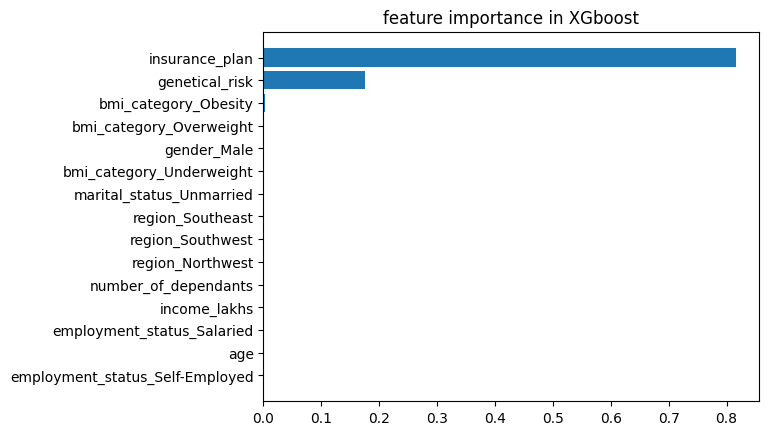

In [74]:
feature_imp=best_model.feature_importances_

coef_df=pd.DataFrame(feature_imp,index=x_test.columns,columns=['Coefficients'])
coef_df=coef_df.sort_values(by='Coefficients',ascending=True)
coef_df

plt.barh(coef_df.index,coef_df['Coefficients'])
plt.title('feature importance in XGboost')
plt.show()

# Error Analysis

In [75]:
y_pred=best_model.predict(x_test)

residuals=y_pred-y_test
residuals_pct=residuals*100/y_test

result_df=pd.DataFrame({
    'actual':y_test,
    'predicted':y_pred,
    'diff':residuals,
    'diff_pct':residuals_pct
})

result_df.head()

,actual,predicted,diff,diff_pct
12774,6238,6456.510254,218.510254,3.502890
14758,9462,9212.351562,-249.648438,-2.638432
13205,5152,5309.856934,157.856934,3.063993
14278,6988,7156.447754,168.447754,2.410529
19351,4917,5373.897949,456.897949,9.292210


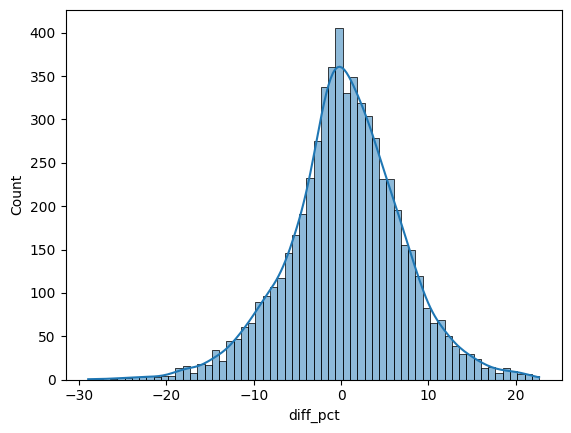

In [76]:
sns.histplot(result_df['diff_pct'],kde=True)
plt.show()

In [77]:
extreme_error_threshold=10
extreme_result_df=result_df[np.abs(result_df.diff_pct)>extreme_error_threshold]
extreme_result_df.shape

(754, 4)

In [78]:
extreme_errors_pct=extreme_result_df.shape[0]*100/result_df.shape[0]
extreme_errors_pct

12.512446067042815

In [79]:
result_df[np.abs(result_df.diff_pct)>50].sort_values('diff_pct',ascending=False)

,actual,predicted,diff,diff_pct


# Export model for young dataset 

In [ ]:
from joblib import dump

dump(best_model,'artifacts/model_young.joblib')

scaler_with_cols={
    'scaler':scaler,
    'cols_to_scale':cols_to_scale
}
dump(scaler_with_cols,'artifacts/scaler_young.joblib')

['app/artifacts/scaler_young.joblib']